# Coin-M BTC DCA Ladder Strategy: Assumptions, Execution, and Robustness

This notebook implements and evaluates a Dollar-Cost-Averaging (DCA) ladder strategy on Bitcoin using coin-margined perpetual futures mechanics.

Key features:
- Deterministic fills (no randomness)
- Coin-margined funding fees applied in coin units
- Liquidation derived from wallet balance and maintenance margin
- Dynamic leverage cap tied to wallet balance
- Commissions and slippage costs
- Performance and risk metrics (Sharpe, Sortino, Calmar, Max Drawdown, VaR/ES)
- Clean plots and cycle-level reporting

### 1) Quick start

- Run all cells top-to-bottom to reproduce the in-sample (IS) and out-of-sample (OOS) results.
- Inputs
  - Data: BTC-USD daily OHLC from BTC-USD_Historical.csv (2015+)
  - Funding: constant daily rate unless a series is provided
- Outputs
  - Summary metrics (Sharpe, Sortino, Calmar, MDD, VaR/ES)
  - Equity curve + drawdowns
  - Cycle-level diagnostics (start/liquidation thresholds)

In [1]:
import math
from dataclasses import dataclass
from typing import Optional, Dict, Any, List, Tuple
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from cycles import compute_previous_cycle_ath, compute_objective_end_date, next_halving_date

from buying_strategy import ladder
from metrics import compute_drawdowns, sortino_ratio, sharpe_ratio, lo_variance_inflation, adjusted_sharpe_lo, summarize_performance, var_es
from engine import run_backtest
from config import StrategyConfig


  ### 2) Data & preprocessing

- Source: BTC-USD daily OHLC (CSV). Columns used: Date, Open, High, Low, Close.
- Date handling: parsed to UTC-like daily timestamps and sorted.
- History window: clipped to >= 2015-01-01 to support long SMAs and prior-cycle ATH logic.
- Note: If you prefer live retrieval, replace the CSV load with a yfinance download cell (and save to CSV for reproducibility).

In [2]:
# Load full history once
PRICE_CSV_PATH = "BTC-USD_Historical.csv"  # adjust path as needed
price_all = pd.read_csv(PRICE_CSV_PATH)
price_all['Date'] = pd.to_datetime(price_all['Date'])
price_all = price_all.sort_values('Date').reset_index(drop=True)

price_all.head()

# Set the cycle start (e.g., halving date for the IS cycle)
START_DATE = pd.Timestamp('2023-03-20')  # first weekly close above weekly SMA50 and SMA200 (week of 2023-03-19)

# Ensure enough history before START_DATE to compute long weekly SMA and prior-cycle ATH
price_all = price_all[price_all['Date'] >= '2015-01-01'].sort_values('Date').reset_index(drop=True)

price_all.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2015-10-24,276.503998,281.705994,276.503998,281.653992,281.653992,25942400
1,2015-10-25,281.445007,294.058990,281.445007,283.679993,283.679993,45717100
2,2015-10-26,283.627991,285.299988,280.510010,285.299988,285.299988,32108800
3,2015-10-27,285.181000,296.212006,285.007996,293.787994,293.787994,46331800
4,2015-10-28,293.703003,306.330994,293.703003,304.618011,304.618011,50808100


### 3) Cycle windows (IS & OOS)

- In-sample (IS): 2023-03-20 → 2025-01-01, starting at the first weekly close above the weekly SMA50 and SMA200.
- Out-of-sample (OOS): 2025-01-02 → 2025-12-31, calendar year 2025.
- Parameters are selected on IS only and applied unchanged to OOS.


In [3]:
# Fixed windows
# IS : 2023-03-20 -> 2025-01-01 (from first weekly close above weekly SMA50/SMA200)
# OOS: 2025-01-02 -> 2025-12-31 (calendar year 2025)
END_DATE = pd.Timestamp('2025-01-01')
OOS_START_DATE = pd.Timestamp('2025-01-02')
OOS_END_DATE = pd.Timestamp('2025-12-31')

price = price_all[(price_all['Date'] >= START_DATE) & (price_all['Date'] <= END_DATE)].reset_index(drop=True)
price_oos = price_all[(price_all['Date'] >= OOS_START_DATE) & (price_all['Date'] <= OOS_END_DATE)].reset_index(drop=True)
print(f"IS window : {price['Date'].iloc[0].date()} -> {price['Date'].iloc[-1].date()}")
print(f"OOS window: {price_oos['Date'].iloc[0].date()} -> {price_oos['Date'].iloc[-1].date()}")


IS window : 2023-03-20 -> 2025-01-01
OOS window: 2025-01-02 -> 2025-12-31


### 4) Configuration guide

Key parameters (see fields in StrategyConfig):
- initial_margin_btc: Seed collateral (BTC) per cycle
- leverage_limit: Max leverage multiple for sizing
- open_margin_pct: Fraction of initial margin used for the first entry
- take_profit_pct: Close the position when gain ≥ this fraction
- commission_rate, slippage_bps: Applied to every fill (entry/scale/exit)
- constant_funding_daily: Daily funding (fallback if no series is supplied)
- maintenance_margin_rate: Used in liquidation calculations
- stop_on_liquidation: Stop trading for the cycle if liquidation occurs
- forced_close_on_last_day: Force an exit on the last day of the window
- contract_model: 'inverse' (BTC-margined perp) or 'linear' (simplified path)

### 5) Contract mechanics (summary)

- Inverse perps (default):
  - Track USD notional q and entry E; unrealized PnL in BTC is q·(1/E − 1/P)
  - Funding and commission are deducted in BTC terms
  - Liquidation price uses wallet BTC excl. unrealized PnL and maintenance margin
- Linear (legacy simplified path):
  - Track position size in BTC; unrealized PnL ≈ size·(P − E)/P
- Execution model:
  - Deterministic fills (close-based by default) with slippage & commission applied
  - Optional T+1 execution can be added if desired to remove any look-ahead doubt

### 6) Backtest execution flow

Per day within a cycle:
1) If not in a position: seed wallet with initial_margin_btc and open using open_margin_pct
2) Apply funding (BTC) per model and rate
3) Recompute liquidation price; if Low ≤ liq_price, mark liquidation and (optionally) stop
4) Apply ladder rules for scale-in (buying_strategy.ladder)
5) Check take-profit and end-of-window forced close
6) Record daily equity, PnL, leverage, and diagnostics

Notes:
- Slippage + commission are applied to all entries and exits (including ladder adds).
- Liquidation logic is an approximation of exchange mechanics.

### 7) Performance metrics

Reported (daily):
- Sharpe, Sortino (downside risk), Calmar (CAGR/MDD), Max Drawdown
- Tail risk: VaR and ES (95%)
- Lo-adjusted Sharpe: corrects for serial correlation (variance inflation)
Outputs:
- IS and OOS summaries printed; CSV saved under results/ if enabled

In [4]:
cfg = StrategyConfig(
    initial_margin_btc=1.0,
    leverage_limit=1.3,
    open_margin_pct=0.02,
    take_profit_pct=0.2,
    commission_rate=0.0004,
    slippage_bps=0.5,
    constant_funding_daily=0.1/365.0,
    maintenance_margin_rate=0.005,
    stop_on_liquidation=True,
    forced_close_on_last_day=True,
    deterministic_fills=True,
    contract_model='inverse'  # explicit
)

res = run_backtest(price, cfg)

perf = res['perf'].copy()
status = res.get('status', {})
cycles = res.get('cycles', [])

summary = summarize_performance(perf)
summary

{'Final Equity (USD)': 122955.02929061017,
 'Total Return (%)': 342.82022740168685,
 'CAGR (%)': 129.72826092485684,
 'Sharpe (Lo-Adj)': np.float64(1.7032545463330298),
 'Sharpe': np.float64(1.727623465042483),
 'Sortino': np.float64(2.8461851411945673),
 'Max Drawdown (%)': np.float64(-30.32807346650027),
 'Longest DD (days)': 229,
 'VaR 95% (%)': np.float64(-4.4472326552831145),
 'ES 95% (%)': np.float64(-6.010115848145372),
 'Final Equity (BTC)': 1.3022171644919476,
 'Total Return BTC (%)': np.float64(30.225857278240873),
 'Max Drawdown BTC (%)': np.float64(-12.84715294163828),
 'Longest DD BTC (days)': 101}

### 8) Plots & interpretation

- Equity curve with drawdown region
- Optionally annotate major cycle boundaries and liquidation points
- Interpretation guide:
  - Smooth, consistent equity growth across IS → OOS is preferred
  - Watch for concentration of gains (few big days) and long drawdown tails
  - Validate that TP events and scale-ins align with the ladder logic

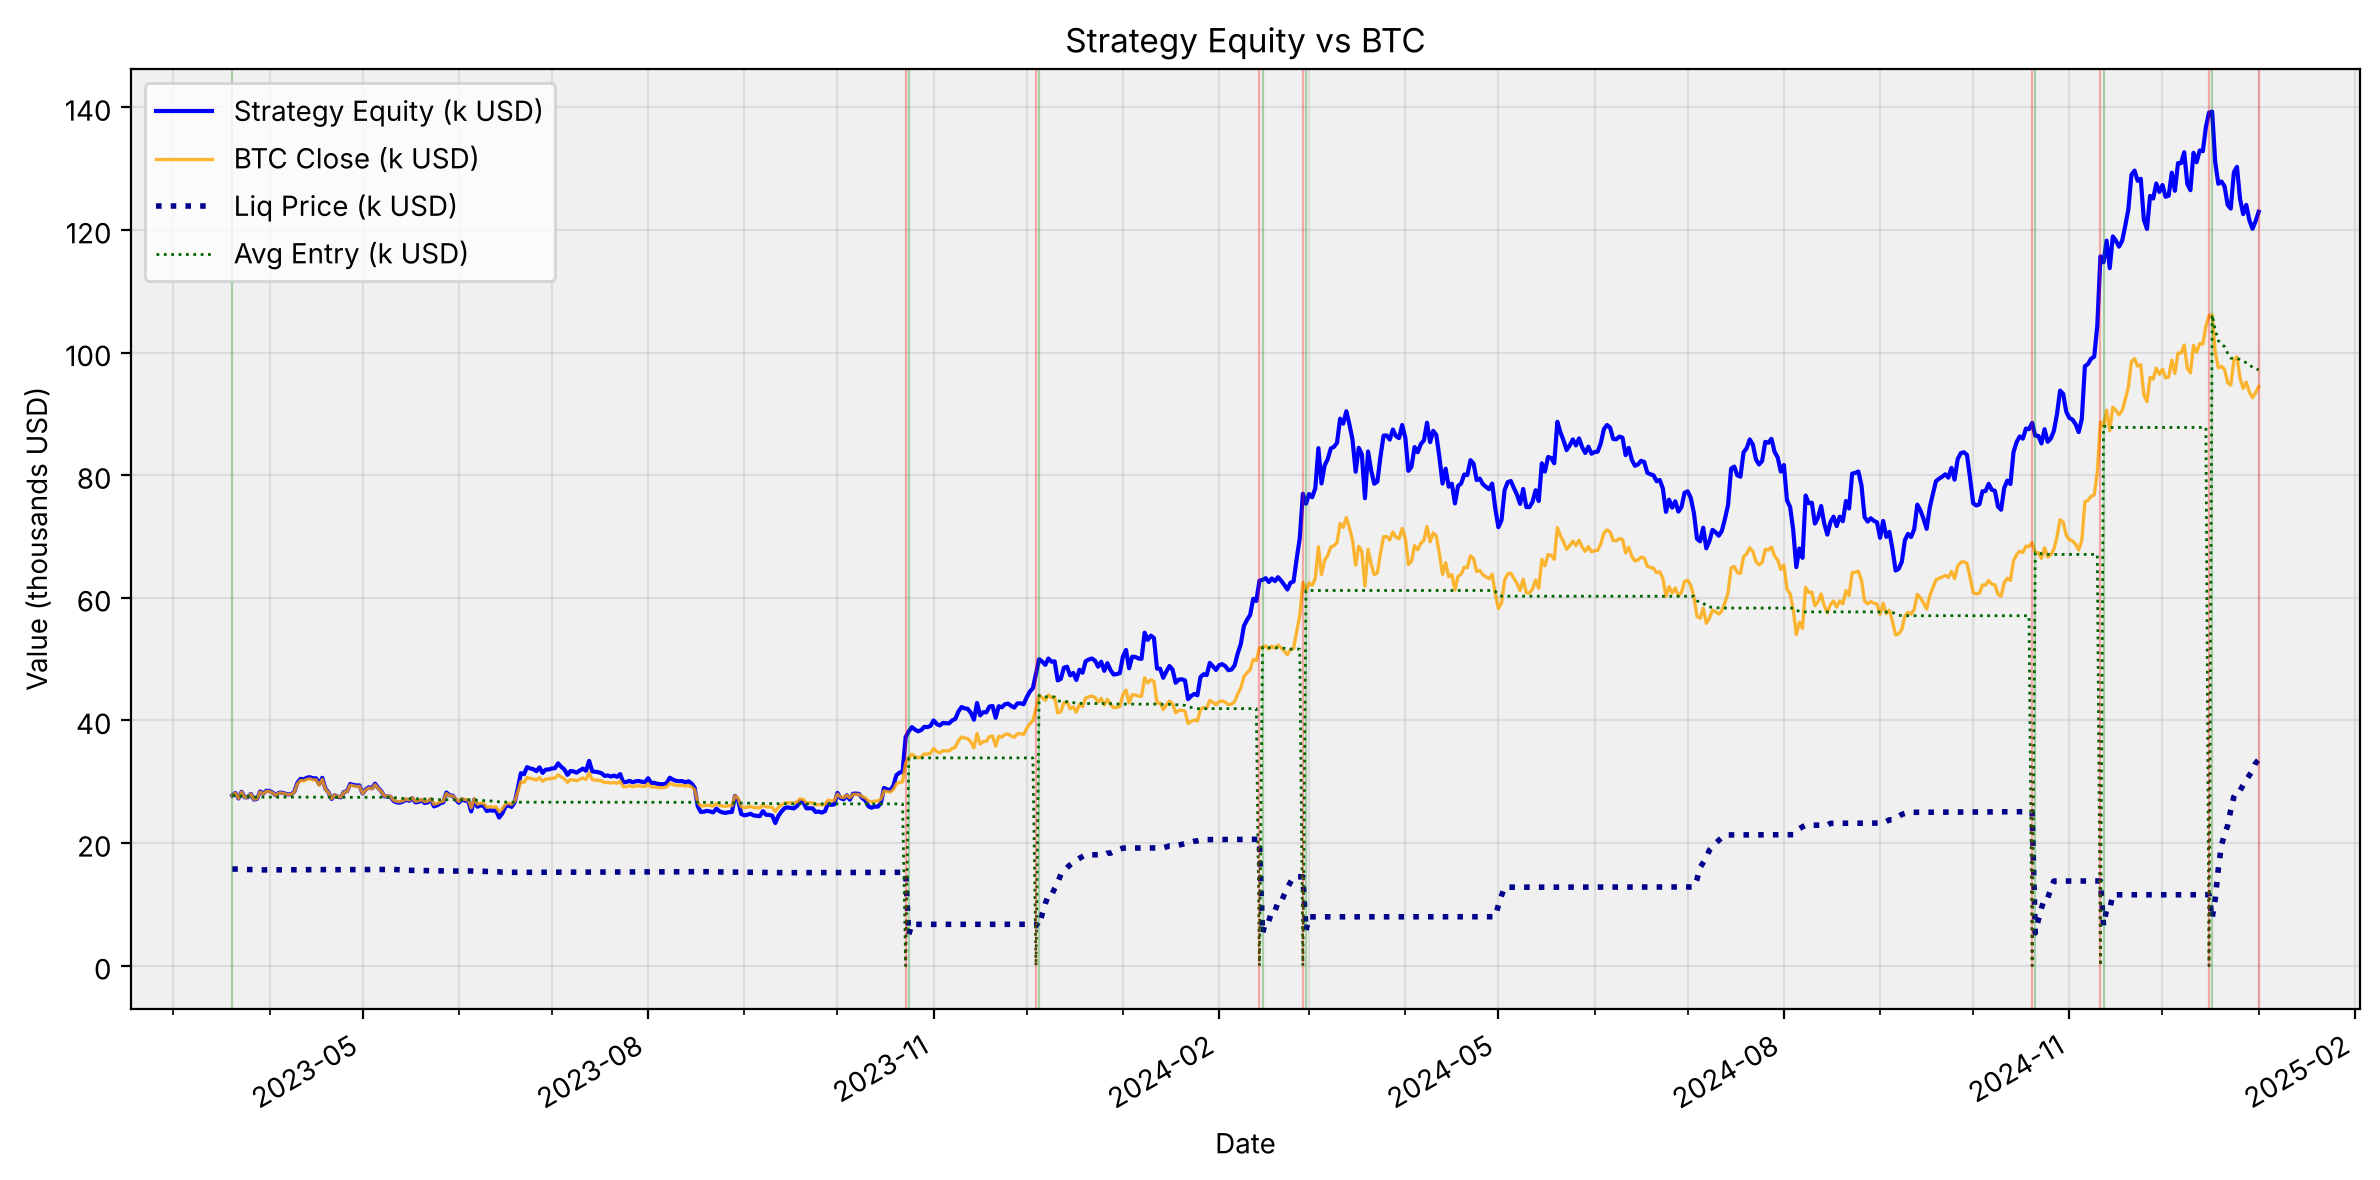

In [5]:
# Assuming perf and status are already defined from earlier cells
if not perf.empty:
    plt.figure(figsize=(12, 6))
    # Normalize equity and BTC price for a visual compare (scale to thousands for readability)
    plt.plot(perf['Date'], perf['Equity_USD'] / 1000.0, label='Strategy Equity (k USD)', color='blue', linewidth=1.5)
    plt.plot(perf['Date'], perf['Close'] / 1000.0, label='BTC Close (k USD)', color='orange', linewidth=1.2, alpha=0.8)

    # Components (uncomment if you want them back)
    #plt.plot(perf['Date'], (perf['Free_Margin_BTC'] * perf['Close']) / 1000.0,
    #         '--', label='Free Margin (k USD)', color='steelblue', linewidth=1.0)
    #plt.plot(perf['Date'], (perf['Pos_Margin_BTC'] * perf['Close']) / 1000.0,
    #         '--', label='Pos Margin (k USD)', color='black', linewidth=1.0)
    #plt.plot(perf['Date'], (perf['Spot_BTC'] * perf['Close']) / 1000.0,
    #         '*', label='Spot (k USD)', color='green', alpha=0.4, linewidth=0.3)

    # Liq and average entry (scaled)
    plt.plot(perf['Date'], perf['Liq_Price_Pre'] / 1000.0, ':', label='Liq Price (k USD)', color='darkblue', linewidth=2.0)
    plt.plot(perf['Date'], perf['Avg_Entry'] / 1000.0, ':', label='Avg Entry (k USD)', color='darkgreen', linewidth=1.0)

    # Cycle markers
    for d in status['starts']:
        plt.axvline(d, color='green', alpha=0.3, linewidth=0.8)
    for d in status['ends']:
        plt.axvline(d, color='red', alpha=0.3, linewidth=0.8)

    plt.title('Strategy Equity vs BTC')
    plt.xlabel('Date')

    # ----------------- key changes -----------------
    ax = plt.gca()

    # 1) Removed logarithmic y-axis (now linear scale)
    ax.set_ylabel('Value (thousands USD)')

    # 2) Denser time labels: major ticks every quarter, minor every month
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))      # Jan-Apr-Jul-Oct
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.xaxis.set_minor_locator(mdates.MonthLocator())                # all months
    # ------------------------------------------------

    # Additional fix for visibility: Set a light gray background to contrast with white lines/backgrounds
    # (This helps if the image appears "white" on light themes like GitHub)
    ax.set_facecolor('#f0f0f0')  # Light gray background for better contrast

    # Ensure lines are darker for visibility on white/light backgrounds
    # (Already using blue/orange/darkblue/darkgreen, which should be fine, but you can adjust if needed)

    plt.legend(loc='best')
    plt.grid(True, alpha=0.3, which='both')  # grid on major & minor ticks
    plt.gcf().autofmt_xdate()                # rotate & align labels nicely
    plt.tight_layout()

    # Save the figure as PNG (high resolution for README)
    plt.show()  # Displays the plot in your notebook

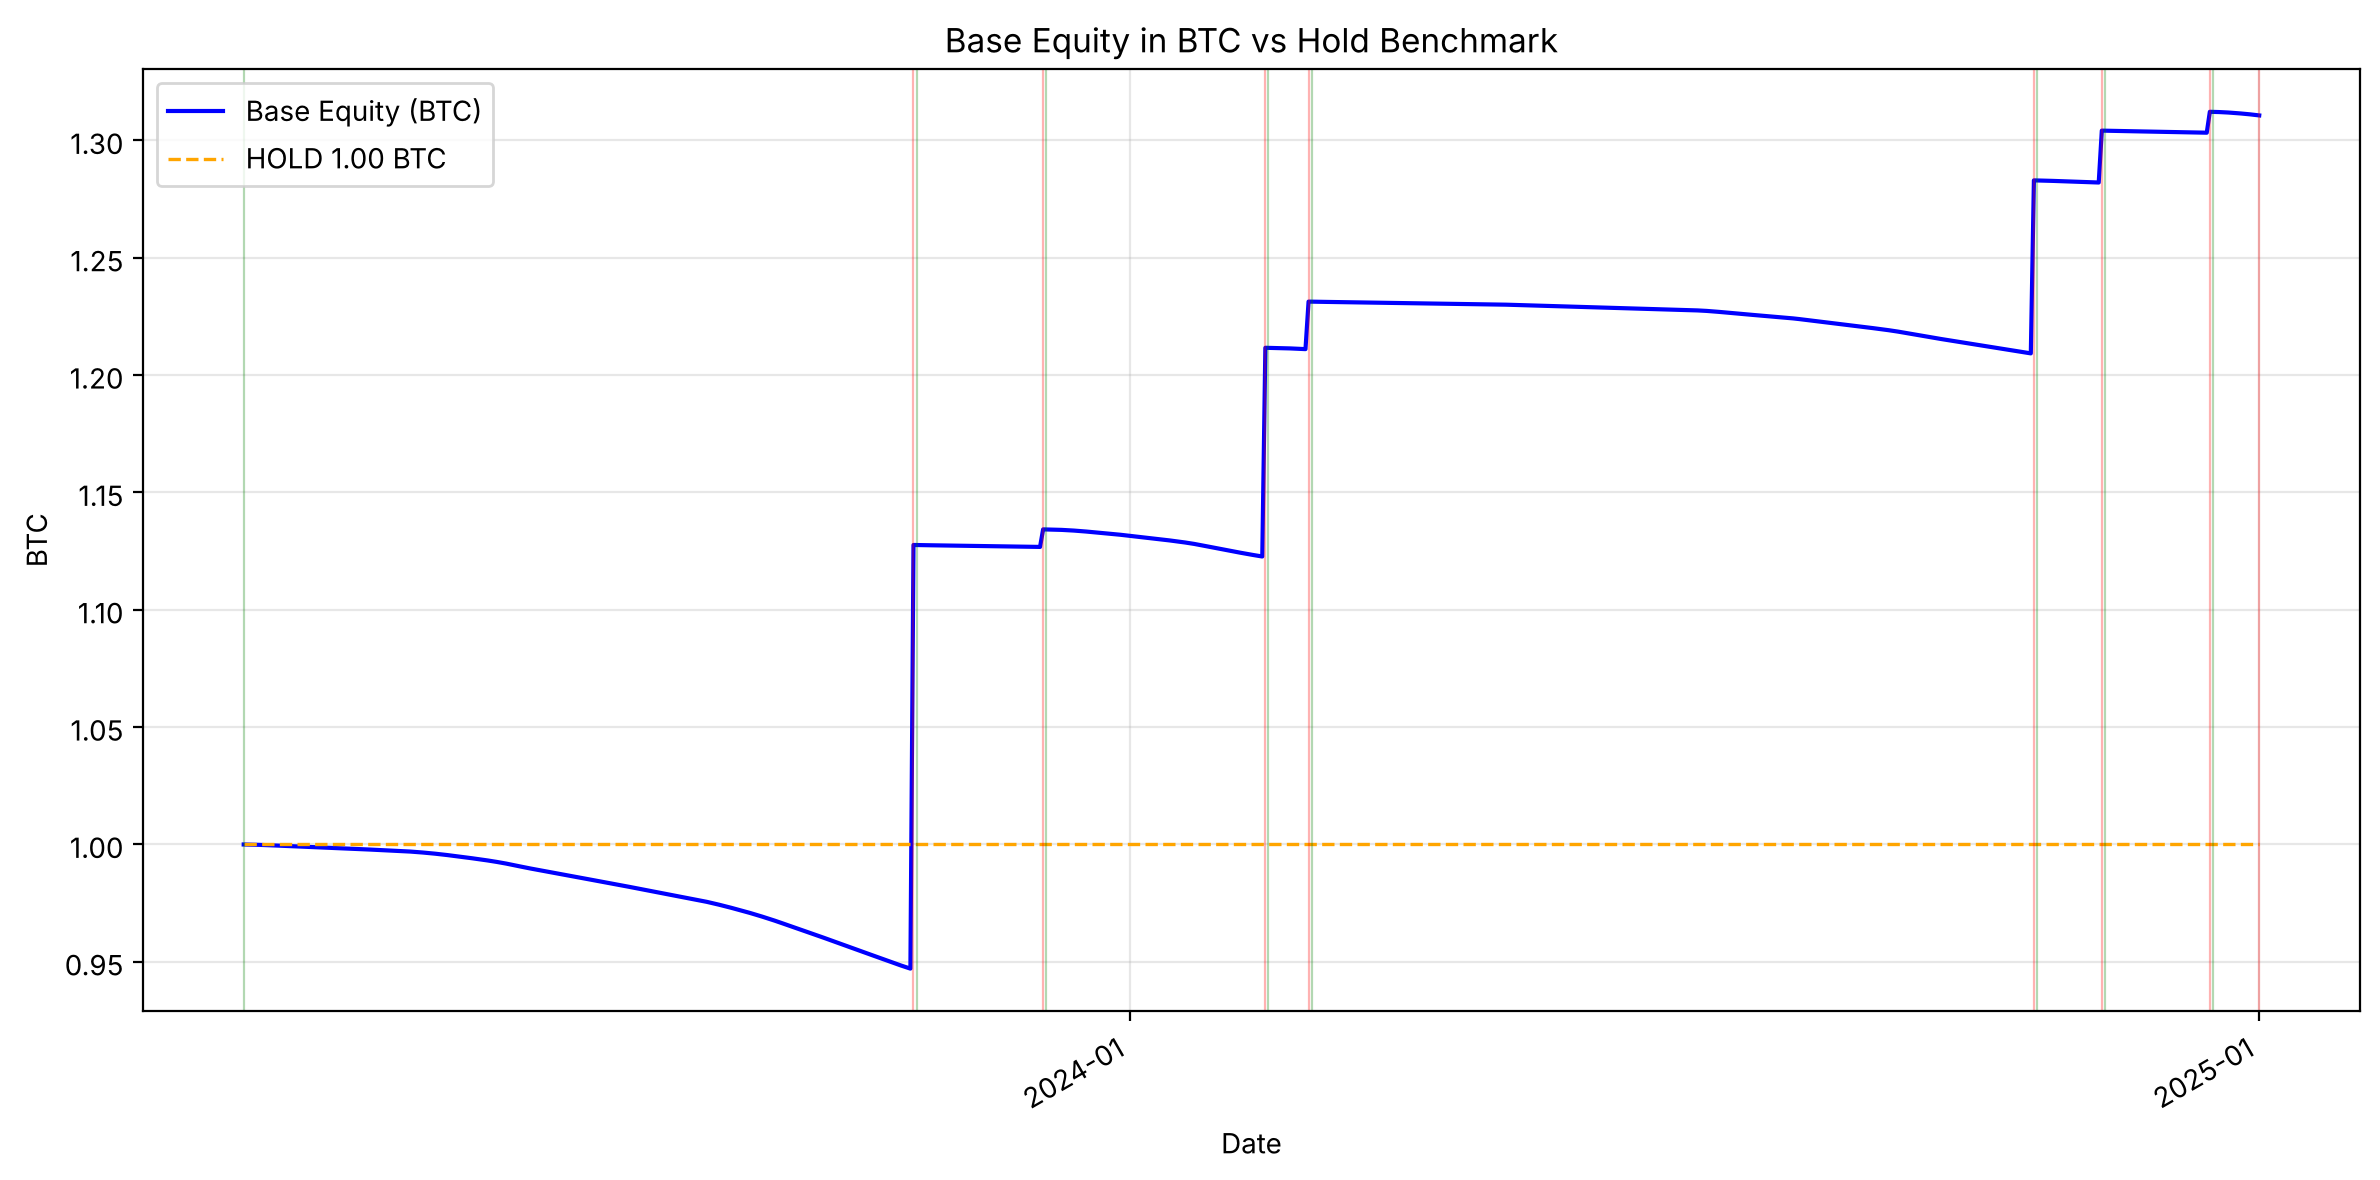

In [6]:
if not perf.empty:
    plt.figure(figsize=(12, 6))
    plt.plot(perf['Date'], perf['Base_Equity_BTC'], label='Base Equity (BTC)', color='blue', linewidth=1.5)
    plt.plot(perf['Date'], np.full(len(perf), cfg.initial_margin_btc), '--', label=f'HOLD {cfg.initial_margin_btc:.2f} BTC', color='orange', linewidth=1.2)

    for d in status['starts']:
        plt.axvline(d, color='green', alpha=0.3, linewidth=0.8)
    for d in status['ends']:
        plt.axvline(d, color='red', alpha=0.3, linewidth=0.8)

    plt.title('Base Equity in BTC vs Hold Benchmark')
    plt.xlabel('Date')
    plt.ylabel('BTC')
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    ax = plt.gca()
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.xaxis.set_major_locator(mdates.YearLocator())
    plt.gcf().autofmt_xdate()
    plt.tight_layout()
    plt.show()

In [7]:
if cycles:
    print("Cycle Details:")
    print("="*160)
    print(f"{'Cycle':<6} {'Start Date':<12} {'End Date':<12} {'Reason':<16} {'Days':<5} "
          f"{'Start Eq (BTC)':<15} {'End Eq (BTC)':<15} "
          f"{'Start Px':<12} {'End Px':<12} "
          f"{'Start Liq':<12} "
          f"{'ΔBTC':<12}")
    print("-"*160)
    for cy in cycles:
        if 'end_date' not in cy:
            continue
        start_eq_btc = cy['start_equity_btc_excl_unreal']
        end_eq_btc = cy['end_equity_btc_excl_unreal']
        btc_change = end_eq_btc - start_eq_btc
        start_liq = cy.get('start_liq_price', np.nan)
        #end_liq = cy.get('last_liq_price', np.nan)
        print(f"{cy['cycle']:<6} "
              f"{cy['start_date'].strftime('%Y-%m-%d'):<12} "
              f"{cy['end_date'].strftime('%Y-%m-%d'):<12} "
              f"{cy.get('reason',''): <16} "
              f"{cy.get('duration_days',0):<5} "
              f"{start_eq_btc: <15.6f} "
              f"{end_eq_btc: <15.6f} "
              f"{cy['start_price']: <12.2f} "
              f"{cy['end_price']: <12.2f} "
              f"{(start_liq if pd.notna(start_liq) else float('nan')): <12.2f} "
              #f"{(end_liq if pd.notna(end_liq) else float('nan')): <12.2f} "
              f"{btc_change:+.6f}")

Cycle Details:
Cycle  Start Date   End Date     Reason           Days  Start Eq (BTC)  End Eq (BTC)    Start Px     End Px       Start Liq    ΔBTC        
----------------------------------------------------------------------------------------------------------------------------------------------------------------
1      2023-03-20   2023-10-23   TAKE-PROFIT      217   0.999990        1.127613        27768.62     33084.58     15773.79     +0.127623
2      2023-10-24   2023-12-04   TAKE-PROFIT      41    1.127603        1.134258        33903.22     41978.00     5102.68      +0.006655
3      2023-12-05   2024-02-14   TAKE-PROFIT      71    1.134248        1.211643        44082.85     51824.10     6390.20      +0.077395
4      2024-02-15   2024-02-28   TAKE-PROFIT      13    1.211632        1.231325        51941.15     62501.66     5267.85      +0.019692
5      2024-02-29   2024-10-20   TAKE-PROFIT      234   1.231314        1.282988        61201.44     68998.25     5766.50      +0.051673

In [8]:
def make_cfg(base_cfg: StrategyConfig, **overrides) -> StrategyConfig:
    # Create a copy with selected overrides
    params = base_cfg.__dict__.copy()
    params.update(overrides)
    return StrategyConfig(**params)

# Define a compact but meaningful grid. Keep it small to avoid overfitting and runtime blowups.
param_grid = {
    'leverage_limit': [2, 3, 4, 5],
    'take_profit_pct': [0.04, 0.05, 0.06, 0.08, 0.10],
    'open_margin_pct': [0.01, 0.02, 0.03, 0.04, 0.05, 0.06],
}

def grid_sweep(price_df: pd.DataFrame,
               base_cfg: StrategyConfig,
               param_grid: dict,
               primary_metric: str = 'Sharpe (Lo-Adj)',
               secondary_metric: str = 'CAGR (%)',
               penalty_on_dd: bool = False) -> pd.DataFrame:
    """
    Run a grid search over param_grid on price_df using base_cfg as defaults.
    Returns a DataFrame sorted by:
      1) non-liquidated first,
      2) primary metric (desc),
      3) secondary metric (desc),
      4) Total Return (desc).
    Optionally apply a soft penalty on large drawdowns to the primary metric.
    """
    keys = list(param_grid.keys())
    combos = list(product(*[param_grid[k] for k in keys]))
    rows = []

    for combo in combos:
        overrides = dict(zip(keys, combo))
        cfg = make_cfg(base_cfg, **overrides)
        res = run_backtest(price_df, cfg)
        perf = res['perf']
        summ = summarize_performance(perf)

        # Guard for empty or degenerate runs
        if not summ:
            continue

        rank_primary = summ.get(primary_metric, np.nan)
        rank_secondary = summ.get(secondary_metric, np.nan)
        max_dd = summ.get('Max Drawdown (%)', np.nan)

        # Optional: penalize large drawdowns in the ranking number (softly)
        if penalty_on_dd and not np.isnan(rank_primary) and not np.isnan(max_dd):
            rank_primary = rank_primary - 0.005 * abs(max_dd)

        row = {
            **overrides,
            'IS_' + primary_metric: rank_primary,
            'IS_' + secondary_metric: rank_secondary,
            'IS_Max Drawdown (%)': max_dd,
            'IS_Total Return (%)': summ.get('Total Return (%)', np.nan),
            'IS_Final Equity (USD)': summ.get('Final Equity (USD)', np.nan),
            'IS_Liquidated': res['status']['liquidated'],
            'IS_Final Equity (BTC)': summ.get('Final Equity (BTC)', np.nan),
            'IS_Max Drawdown BTC (%)': summ.get('Max Drawdown BTC (%)', np.nan),
        }
        rows.append(row)

    results = pd.DataFrame(rows)
    if results.empty:
        print("No results from grid sweep.")
        return results

    # Sort with non-liquidated first and then by metrics; NaNs go to the bottom.
    # Use -inf for NaN in ranking columns so they naturally sink on descending sorts.
    pcol = f'IS_{primary_metric}'
    scol = f'IS_{secondary_metric}'
    tcol = 'IS_Total Return (%)'
    for col in [pcol, scol, tcol]:
        if col in results.columns:
            results[col] = results[col].astype(float)
            results[col] = results[col].fillna(-np.inf)

    results = results.sort_values(
        by=['IS_Liquidated', pcol, scol, tcol],
        ascending=[True, False, False, False]
    ).reset_index(drop=True)

    return results

# Run the grid sweep on IS
base_cfg = StrategyConfig(
    initial_margin_btc=1.0,
    leverage_limit=1.2,          # default; will be overridden by grid
    open_margin_pct=0.02,
    take_profit_pct=0.10,
    commission_rate=0.0004,
    slippage_bps=0.5,
    constant_funding_daily=0.10 / 365.0,
    maintenance_margin_rate=0.005,
    stop_on_liquidation=True,
    forced_close_on_last_day=True,
    deterministic_fills=True
)

price_is = price.copy()  # the entire IS window

grid_results_is = grid_sweep(
    price_df=price_is,
    base_cfg=base_cfg,
    param_grid=param_grid,
    primary_metric='Sharpe (Lo-Adj)',
    secondary_metric='CAGR (%)',
    penalty_on_dd=True  # softly prefer lower DD
)

# Selection rule (fixed before looking at OOS):
# not liquidated, max drawdown in BTC terms <= 50%, then maximum final equity in BTC
MAX_DD_BTC = 50.0
eligible = grid_results_is[(~grid_results_is['IS_Liquidated'])
                           & (grid_results_is['IS_Max Drawdown BTC (%)'] >= -MAX_DD_BTC)].copy()
eligible_sorted = eligible.sort_values(by='IS_Final Equity (BTC)', ascending=False).reset_index(drop=True)

with pd.option_context('display.max_rows', 20, 'display.max_columns', None):
    display(eligible_sorted[
        ['leverage_limit', 'take_profit_pct', 'open_margin_pct',
         'IS_Final Equity (BTC)', 'IS_Max Drawdown BTC (%)',
         'IS_Sharpe (Lo-Adj)', 'IS_Max Drawdown (%)', 'IS_Liquidated']
    ].round(3))


,leverage_limit,take_profit_pct,open_margin_pct,IS_Final Equity (BTC),IS_Max Drawdown BTC (%),IS_Sharpe (Lo-Adj),IS_Max Drawdown (%),IS_Liquidated
0,5,0.08,0.06,2.904,-36.133,1.517,-46.663,False
1,5,0.08,0.05,2.847,-34.924,1.522,-45.999,False
2,5,0.10,0.05,2.804,-45.447,1.333,-56.389,False
3,5,0.10,0.06,2.803,-45.527,1.322,-56.453,False
4,5,0.08,0.04,2.795,-32.691,1.534,-45.185,False
...,...,...,...,...,...,...,...,...
115,2,0.04,0.04,1.438,-18.621,1.455,-34.944,False
116,2,0.05,0.01,1.437,-15.702,1.530,-32.611,False
117,2,0.04,0.03,1.390,-18.150,1.449,-34.567,False
118,2,0.04,0.02,1.364,-17.668,1.453,-34.182,False


Best IS parameters: {'leverage_limit': 5, 'take_profit_pct': 0.08, 'open_margin_pct': 0.06}

Best Params — IS Performance
Final Equity (USD): $274,183.76
Total Return (%): 887.7542
CAGR (%): 259.7225
Sharpe (Lo-Adj): 1.7507
Sharpe: 1.7507
Sortino: 2.8624
Max Drawdown (%): -46.6629
Longest DD (days): 98
VaR 95% (%): -6.8785
ES 95% (%): -10.5688
Final Equity (BTC): 2.9039
Total Return BTC (%): 190.4816
Max Drawdown BTC (%): -36.1329
Longest DD BTC (days): 94

Best Params — OOS Performance
Final Equity (USD): $42,433.37
Total Return (%): -56.1891
CAGR (%): -56.3878
Sharpe (Lo-Adj): -0.8056
Sharpe: -1.0411
Sortino: -1.0623
Max Drawdown (%): -67.0975
Longest DD (days): 344
VaR 95% (%): -4.0297
ES 95% (%): -8.4360
Final Equity (BTC): 0.4849
Total Return BTC (%): -51.4940
Max Drawdown BTC (%): -54.2102
Longest DD BTC (days): 344


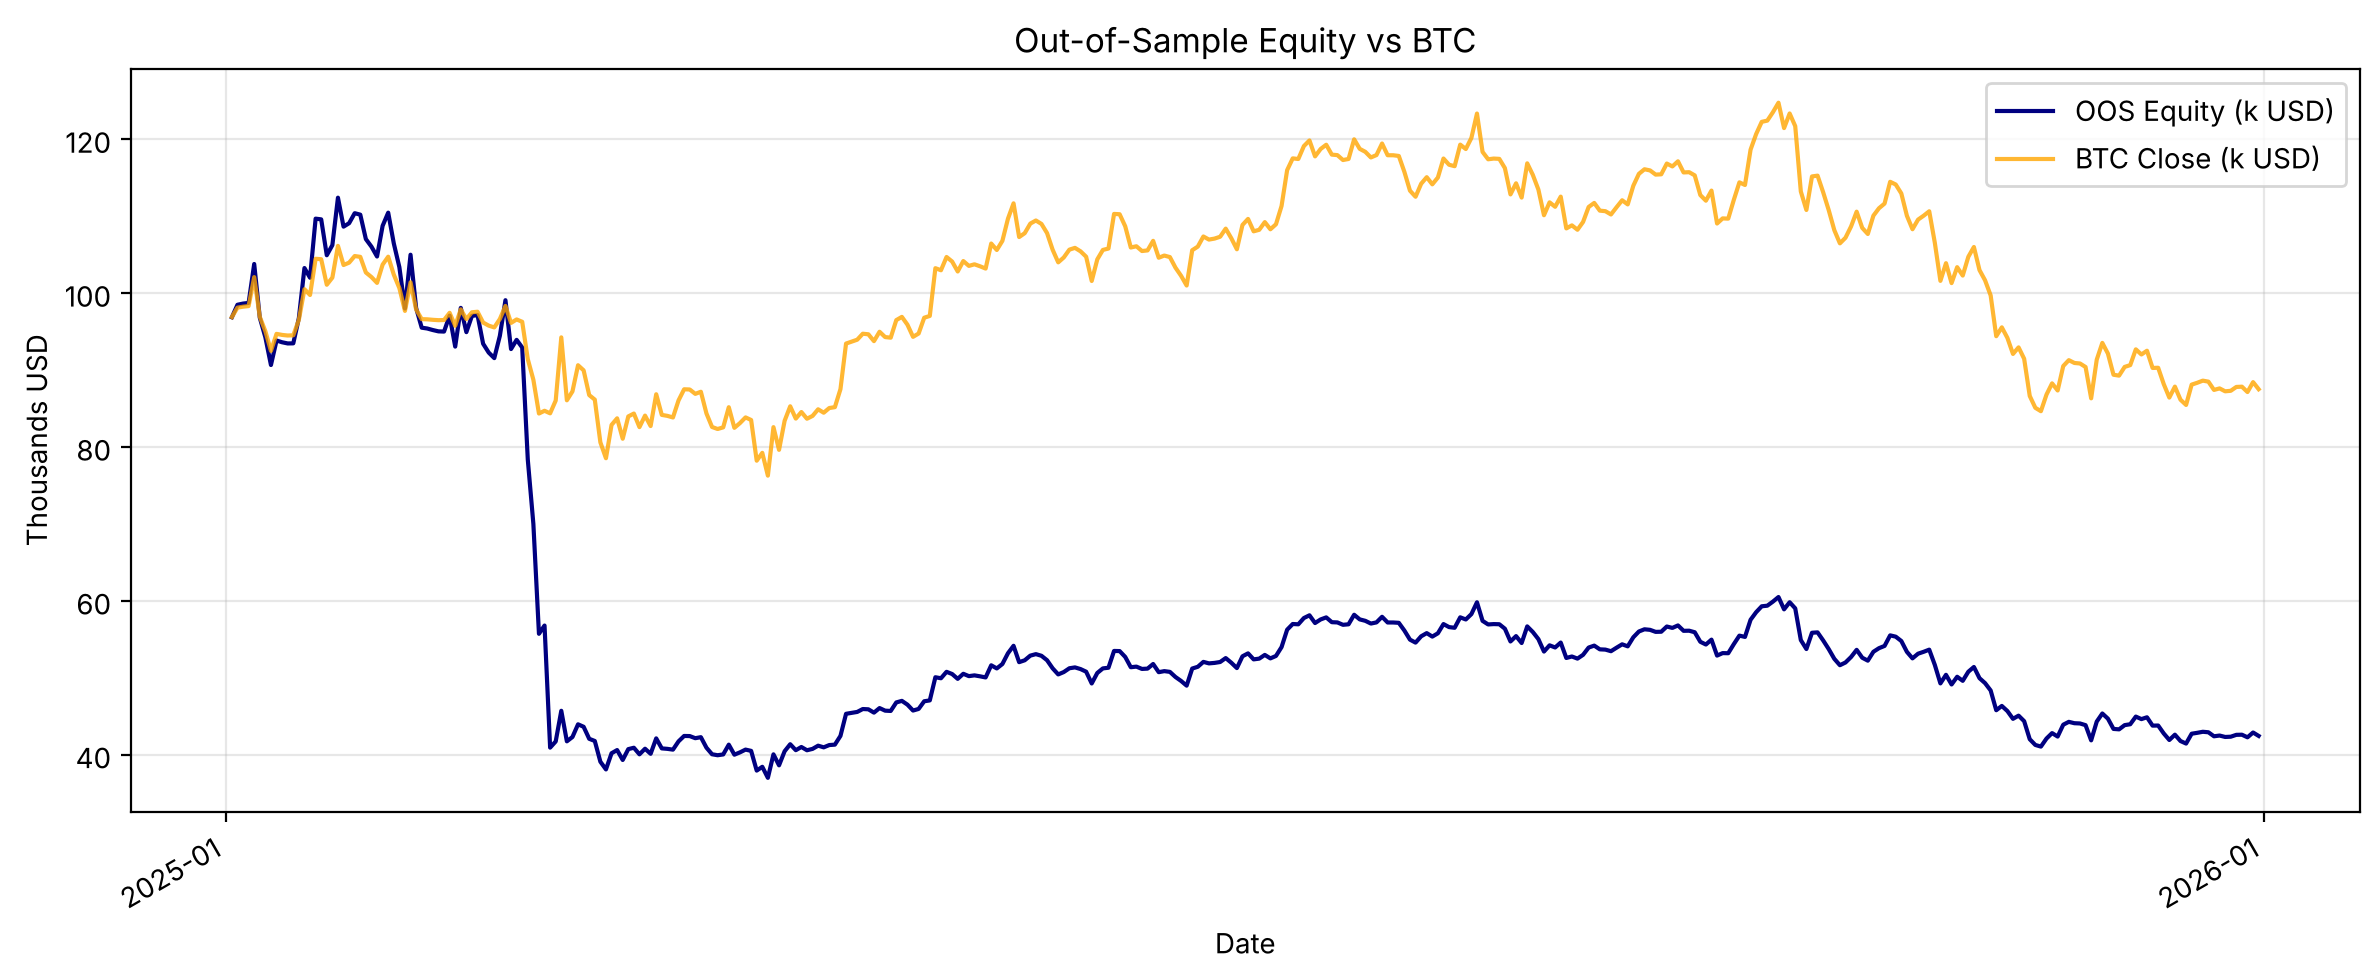

In [9]:
def pick_best_params(grid_df: pd.DataFrame) -> dict:
    if grid_df.empty:
        raise ValueError("Empty grid results; cannot pick best parameters.")
    # First row is best under our sort order
    keys = [k for k in grid_df.columns if k in param_grid.keys()]
    return grid_df.iloc[0][keys].to_dict()

if grid_results_is.empty:
    print("Grid results empty; cannot proceed to OOS.")
else:
    best_params = pick_best_params(eligible_sorted)
    print("Best IS parameters:", best_params)

    # Evaluate on OOS (fresh run with same params)
    best_cfg_oos = make_cfg(base_cfg, **best_params)
    res_oos = run_backtest(price_oos, best_cfg_oos)
    perf_oos = res_oos['perf']
    summary_oos = summarize_performance(perf_oos)

    # For reference, also capture IS performance of best params (not the whole grid)
    best_cfg_is = make_cfg(base_cfg, **best_params)
    res_is_best = run_backtest(price_is, best_cfg_is)
    perf_is_best = res_is_best['perf']
    summary_is_best = summarize_performance(perf_is_best)

    print("\nBest Params — IS Performance")
    for k, v in summary_is_best.items():
        if isinstance(v, float):
            if k == 'Final Equity (USD)':
                print(f"{k}: ${v:,.2f}")
            else:
                print(f"{k}: {v:.4f}")
        else:
            print(f"{k}: {v}")

    print("\nBest Params — OOS Performance")
    if not summary_oos:
        print("OOS period empty or invalid.")
    else:
        for k, v in summary_oos.items():
            if isinstance(v, float):
                if k == 'Final Equity (USD)':
                    print(f"{k}: ${v:,.2f}")
                else:
                    print(f"{k}: {v:.4f}")
            else:
                print(f"{k}: {v}")

    # Optional: plot OOS equity
    if perf_oos is not None and not perf_oos.empty:
        plt.figure(figsize=(12, 5))
        plt.plot(perf_oos['Date'], perf_oos['Equity_USD'] / 1000.0, label='OOS Equity (k USD)', color='navy')
        plt.plot(perf_oos['Date'], perf_oos['Close'] / 1000.0, label='BTC Close (k USD)', color='orange', alpha=0.8)
        plt.title('Out-of-Sample Equity vs BTC')
        plt.xlabel('Date')
        plt.ylabel('Thousands USD')
        plt.legend(loc='best')
        plt.grid(True, alpha=0.3)
        ax = plt.gca()
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax.xaxis.set_major_locator(mdates.YearLocator())
        plt.gcf().autofmt_xdate()
        plt.tight_layout()
        plt.show()

### 11) README figure: selected parameters, IS and OOS in BTC terms


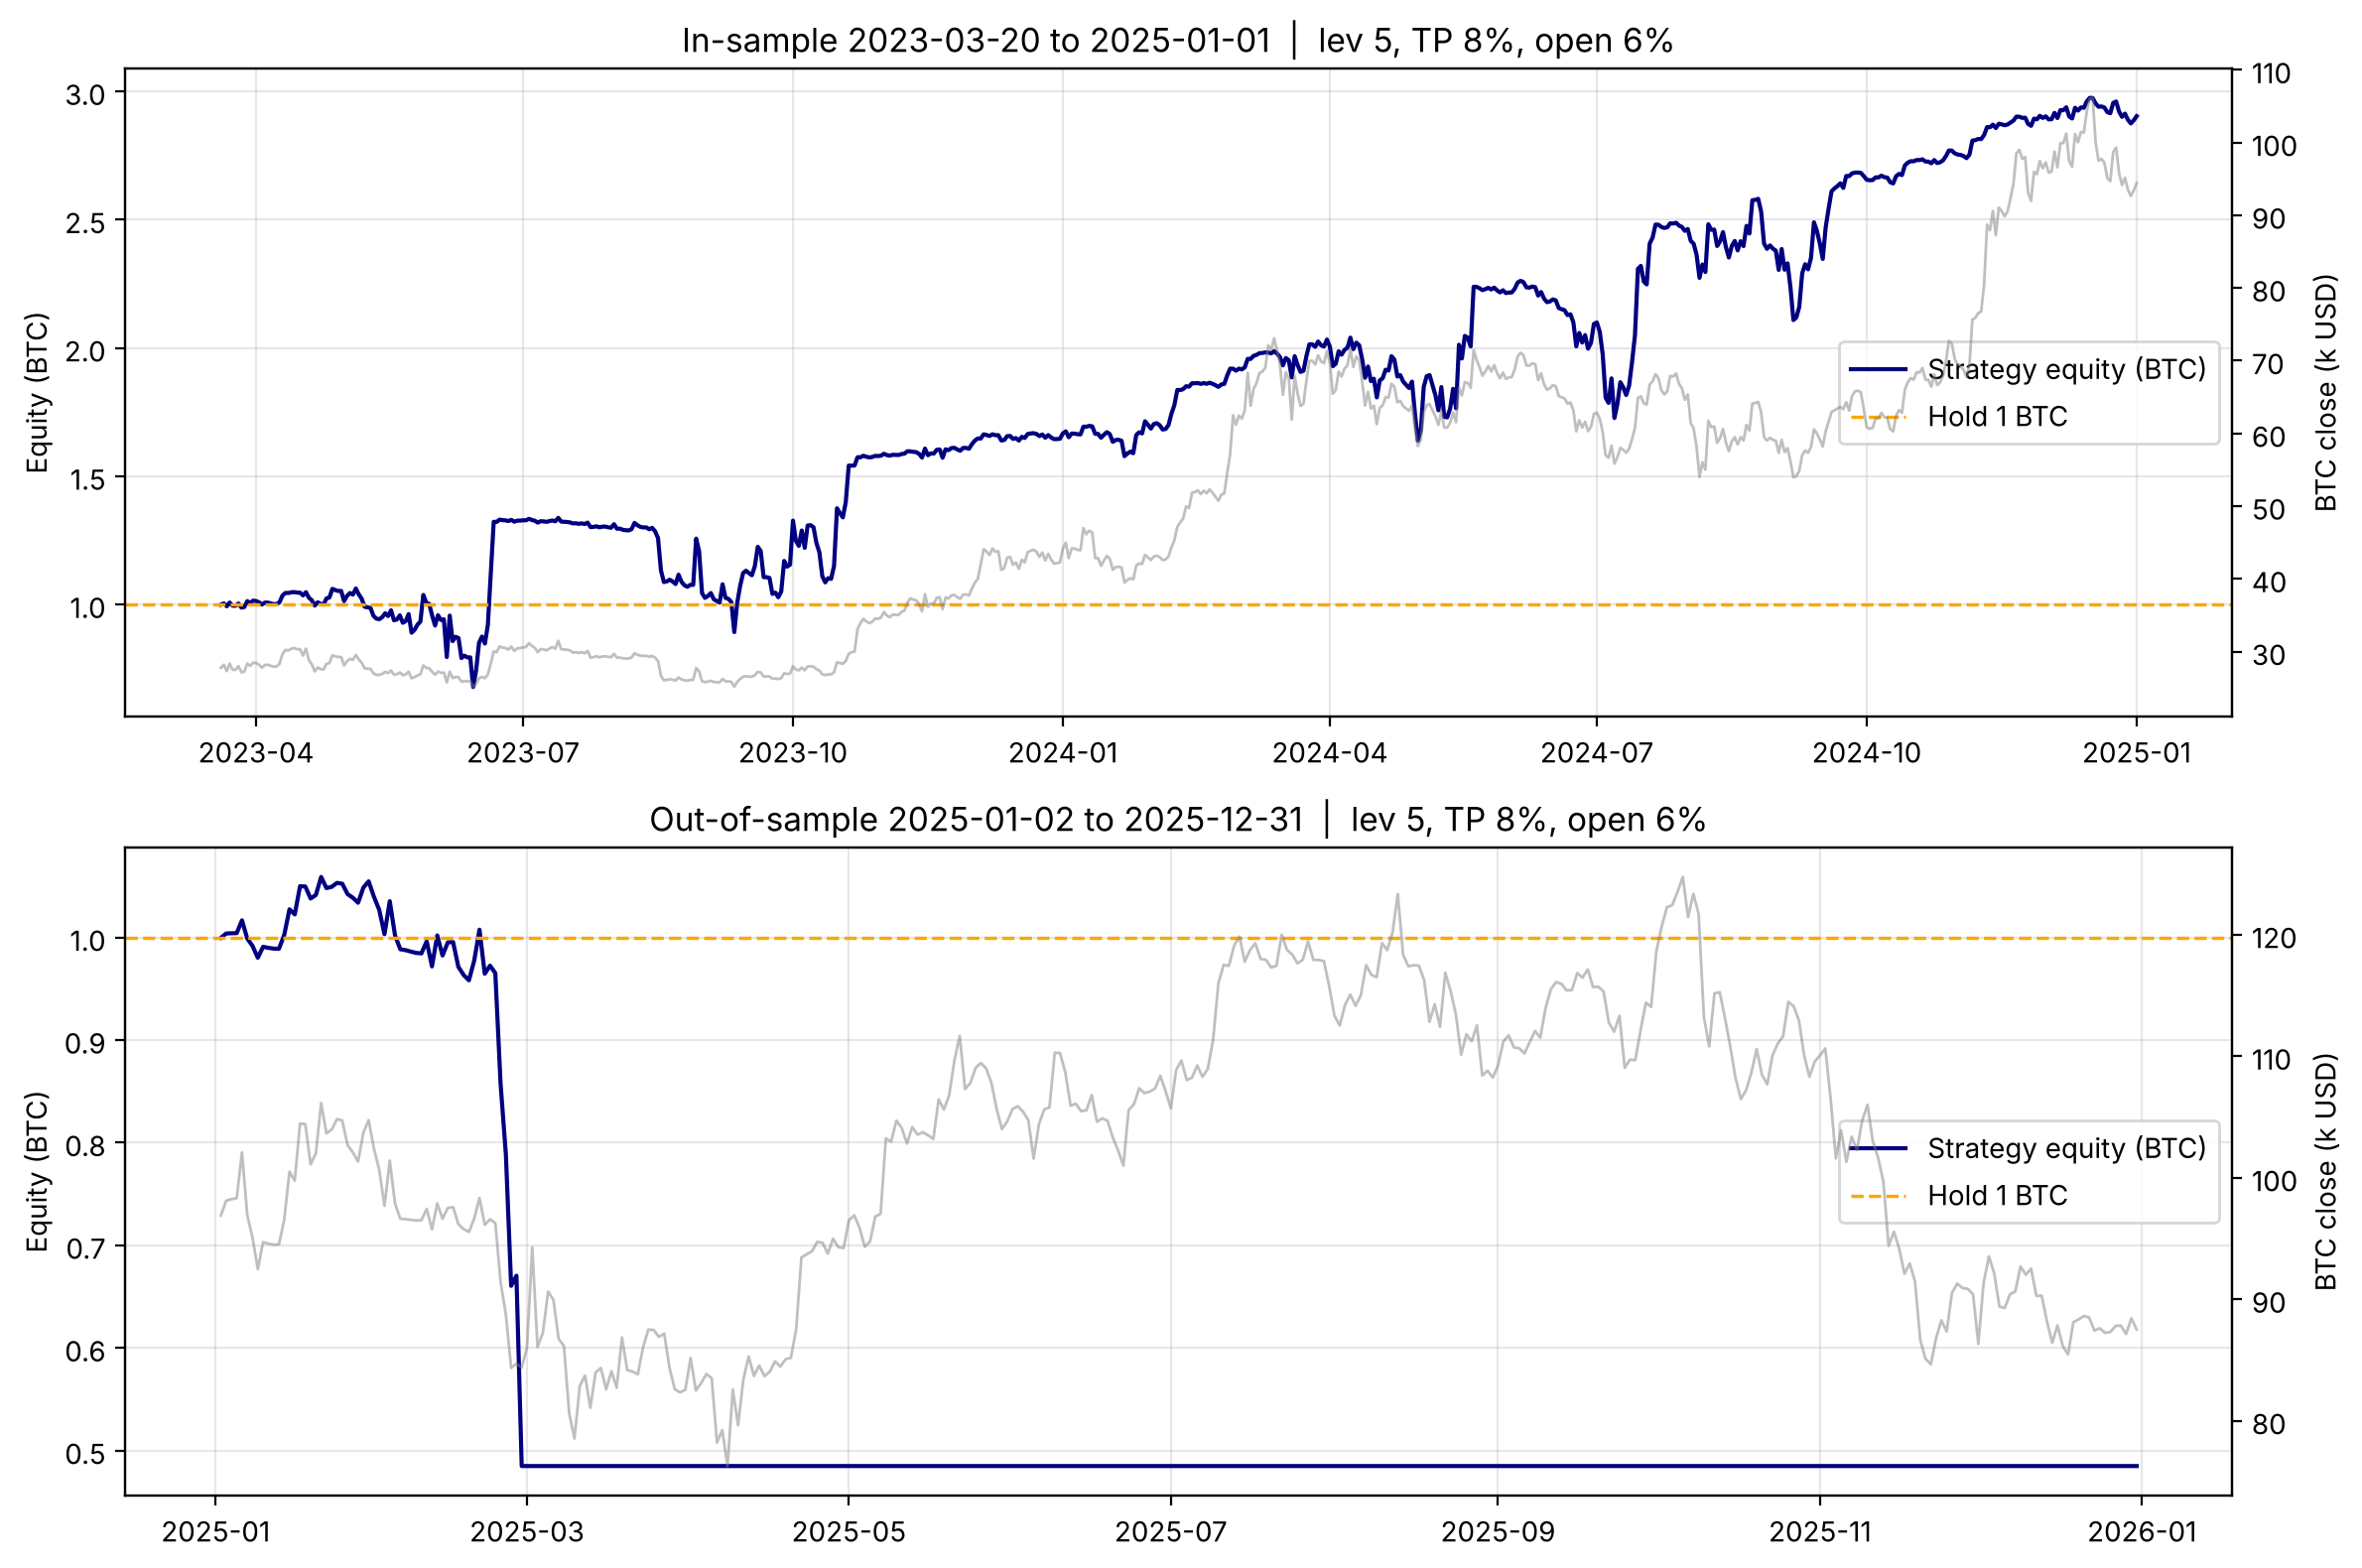

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=False)
for ax, (label, pf) in zip(axes, [('In-sample', perf_is_best), ('Out-of-sample', perf_oos)]):
    eq_btc = pf['Equity_USD'] / pf['Close']
    ax.plot(pf['Date'], eq_btc, color='navy', linewidth=1.5, label='Strategy equity (BTC)')
    ax.axhline(1.0, color='orange', linestyle='--', linewidth=1.2, label='Hold 1 BTC')
    ax2 = ax.twinx()
    ax2.plot(pf['Date'], pf['Close'] / 1000.0, color='grey', alpha=0.5, linewidth=1.0, label='BTC close (k USD)')
    ax2.set_ylabel('BTC close (k USD)')
    title = f"{label} {pf['Date'].iloc[0].date()} to {pf['Date'].iloc[-1].date()}  |  lev {best_params['leverage_limit']}, TP {best_params['take_profit_pct']:.0%}, open {best_params['open_margin_pct']:.0%}"
    ax.set_title(title)
    ax.set_ylabel('Equity (BTC)')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='center right')
plt.tight_layout()
plt.savefig('equity.curve.png', dpi=150, bbox_inches='tight')
plt.show()


### 9) Limitations & assumptions

- Liquidation formula is a simplified approximation (exchange-specific details vary)
- Funding defaults to a constant daily rate unless a historical series is provided
- Daily bars only; intraday path dependency (gap risk) is not modeled
- Close-based fills by default; T+1 execution can be enabled to remove look-ahead

### 10) Reproducibility & outputs

- Environment: Python 3.10+, NumPy, pandas, Matplotlib (see requirements.txt)
- Deterministic: no randomness in fills; results should be repeatable with same data
- Saved artifacts:
  - figures/: equity curve and drawdown plots (PNG)
  - results/: summary tables (CSV) for IS and OOS
- Data note: If BTC-USD_Historical.csv is absent, run the optional download cell to create it